# Apakah Apple Membagikan Lebih Banyak Uang daripada yang Dihasilkan Bisnisnya?

**Informasi strategis:** pembagian uang ke pemegang saham (*buyback* + dividen) dibandingkan dengan arus kas bebas (*free cash flow*, FCF) — Apple Inc., laporan tahunan **10-K**, tahun fiskal 2015–2025.

## Masalahnya

> **Apakah Apple membagikan lebih banyak uang daripada yang dihasilkan bisnisnya?**

Ukurannya adalah rasio:

$$\text{Rasio} = \frac{\text{Buyback} + \text{Dividen}}{\text{FCF}} \times 100\%$$

Dengan:
- **FCF** = kas dari aktivitas operasi − belanja pabrik dan peralatan (*capex*)
- **Rasio > 100%** berarti selisihnya dibiayai dari simpanan kas atau pinjaman — uang yang dibagikan melebihi yang dihasilkan bisnis

## Sumber data

SEC EDGAR — API resmi SEC (`companyfacts` dan `submissions`, CIK 0000320193), di-refresh terakhir 2026-10-19. Dataset berisi **25.135 observasi keuangan** dan **1.002 filing**.

## Alur notebook

1. **Untuk siapa** informasi ini → 2. **Membaca file data** → 3. **Mengenal isi data dan arti kolom** → 4. **Menyaring data mentah** → 5. **Grafik dan cara membacanya** → 6. **Jawaban** → 7. **Solusi & batasan**


## Untuk siapa informasi strategis ini?

Informasi ini paling berkepentingan kepada tiga pihak. Posisi tertentu menentukan tindakan yang diambil dari temuan yang sama:

| Pihak | Alasan butuh informasi ini | Keputusan yang terbantu |
|---|---|---|
| **Dewan direksi dan CFO Apple** (utama) | Merekalah yang menetapkan besar buyback dan dividen | Menetapkan batas buyback dan dividen supaya tidak menggerus simpanan |
| **Pemberi pinjaman dan pembeli surat utang** | Menilai apakah pembagian yang besar menambah risiko utang | Menentukan kesediaan meminjam dan syaratnya (mis. bunga) |
| **Investor dividen dan buyback** | Menilai apakah pembagian ini bisa berlanjut | Menambah, menahan, atau mengurangi posisi |

> **Catatan:** ini bukan saran investasi. Angka di sini membantu memahami kondisi perusahaan, tetapi keputusan membeli/menjual saham perlu mempertimbangkan hal lain (termasuk harga saham yang tidak ada di dataset ini).


## 1. Membaca file data

Tiga file yang dibaca (folder `apple_stocks_dataset/`):

| File | Isi |
|---|---|
| `financial_facts.csv` | Semua angka keuangan dari laporan SEC (utama) |
| `filings.csv` | Daftar semua surat/filing Apple yang diserahkan ke SEC (penunjang) |
| `company_profile.json` | Profil perusahaan (CIK, ticker, bursa) |


In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

DATA_DIR = next(
    d for d in ["../apple_stocks_dataset", "apple_stocks_dataset", "."]
    if os.path.exists(f"{d}/financial_facts.csv")
)

facts   = pd.read_csv(f"{DATA_DIR}/financial_facts.csv", parse_dates=["start", "end", "filed"])
filings = pd.read_csv(f"{DATA_DIR}/filings.csv",         parse_dates=["filingDate"])
profile = json.load(open(f"{DATA_DIR}/company_profile.json"))

print(f"Perusahaan : {profile['entityName']} (ticker {profile['ticker']}, bursa {profile['exchanges'][0]})")
print(f"CIK        : {profile['cik']}")
print(f"financial_facts : {facts.shape[0]:,} baris x {facts.shape[1]} kolom")
print(f"filings         : {filings.shape[0]:,} baris x {filings.shape[1]} kolom")

# gaya grafik yang dipakai di seluruh notebook
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
BLUE, ORANGE, RED, GREY = "#2F5D8C", "#E08A2E", "#C0392B", "#6B7280"


Perusahaan : Apple Inc. (ticker AAPL, bursa Nasdaq)
CIK        : 0000320193
financial_facts : 25,135 baris x 14 kolom
filings         : 1,002 baris x 11 kolom


## 2. Mengenal isi data dan arti tiap kolom

Sebelum dihitung, kita perlu tahu: data ini isinya apa, dan tiap kolom maksudnya apa. Kolom yang namanya terlihat seperti "kode" ternyata punya arti sederhana.

### `financial_facts.csv` — kumpulan angka keuangan

Setiap baris = **satu angka** yang dilaporkan Apple ke SEC. Karena satu laporan berisi ratusan angka, satu baris punya penanda: angka apa itu, dari laporan mana, dan untuk periode kapan.

| Kolom | Artinya (penjelasan bebas) |
|---|---|
| `taxonomy` | "Asal kamus" kode standar: `us-gaap` (kamus akuntansi AS) atau `dei` (identitas perusahaan) |
| `concept` | **Nama angka yang dilaporkan.** Contoh: `NetCashProvidedByUsedInOperatingActivities` = kas dari operasi |
| `label` | Nama panjang satu kalimat untuk `concept` — bacaan yang lebih manusiawi |
| `description` | Definisi lengkap angka itu menurut SEC |
| `unit` | Satuan nilai: `USD` (dolar), `shares` (lembar saham), `USD/shares` |
| `value` | **Nilai angkanya.** Ini yang nanti dihitung dan digambar |
| `accn` | Nomor akses surat sumber — jejak audit ke filing asal angka itu |
| `form` | Jenis surat SEC tempat angka muncul: `10-K` = laporan tahunan, `10-Q` = laporan kuartal |
| `filed` | Tanggal surat diserahkan ke SEC |
| `fy`, `fp` | Tahun dan periode fiskal yang ditandai filing (contoh: `2021, Q1`) |
| `start`, `end` | Periode yang dicakup angka. Untuk angka arus (mis. kas setahun), `start`–`end` ≈ 1 tahun. Untuk angka saldo (mis. utang per tanggal), hanya `end` yang terisi |
| `frame` | Kode periode standar SEC, mis. `CY2021Q3I` (kuartal 3 tahun 2021, khusus untuk saldo) |

Yang perlu diingat: **angka yang sama muncul berkali-kali**, karena angka tahun berjalan juga dimunculkan lagi di laporan tahun berikutnya sebagai pembanding. Itulah sebabnya butuh langkah **menangani duplikasi** di bagian 3.

### `filings.csv` — daftar surat yang dikirim ke SEC

| Kolom | Artinya (penjelasan bebas) |
|---|---|
| `accessionNumber` | Nomor akses surat — padanan dari kolom `accn` di facts, untuk mencocokkan angka ke surat sumbernya |
| `filingDate`, `reportDate` | Kapan surat diserahkan, dan periode yang dilaporkan |
| `form` | Jenis surat: `10-K`/`10-Q`, `4` (laporan transaksi petinggi), `8-K` (pengumuman), `424B2` (prospektus surat utang), dll. |
| `primaryDocument` | Nama file utama surat |
| `size`, `isXBRL` | Ukuran surat dan penanda surat itu memakai kode XBRL atau tidak |


In [2]:
print("=" * 46, "financial_facts.csv (3 baris pertama)")
display(facts.head(3))
print(f"Jumlah concept unik: {facts.concept.nunique():,} | Form unik: {facts.form.nunique()}")
print(f"Distribusi form (10 teratas):")
display(facts.form.value_counts().head(10))

print("=" * 46, "filings.csv (3 baris pertama)")
display(filings[["accessionNumber", "filingDate", "form", "primaryDocument"]].head(3))


============================================== financial_facts.csv (3 baris pertama)


,taxonomy,concept,label,description,unit,value,accn,form,filed,fy,fp,start,end,frame
0,dei,EntityCommonStockSharesOutstanding,"Entity Common Stock, Shares Outstanding",Indicate number of shares or other units outst...,shares,8.958168e+08,0001193125-09-153165,10-Q,2009-07-22,2009.0,Q3,NaT,2009-06-27,CY2009Q2I
1,dei,EntityPublicFloat,Entity Public Float,The aggregate market value of the voting and n...,USD,9.459300e+10,0001193125-09-153165,10-Q,2009-07-22,2009.0,Q3,NaT,2009-03-28,NaN
2,us-gaap,AccountsPayable,Accounts Payable (Deprecated 2009-01-31),Carrying value as of the balance sheet date of...,USD,5.520000e+09,0001193125-09-153165,10-Q,2009-07-22,2009.0,Q3,NaT,2008-09-27,CY2008Q3I


Jumlah concept unik: 505 | Form unik: 4
Distribusi form (10 teratas):


form
10-Q      15304
10-K       8503
8-K        1118
10-K/A      210
Name: count, dtype: int64

============================================== filings.csv (3 baris pertama)


,accessionNumber,filingDate,form,primaryDocument
0,0001140361-26-040127,2026-10-19,4,xslF345X06/form4.xml
1,0001140361-26-040126,2026-10-19,4,xslF345X06/form4.xml
2,0001950047-26-010286,2026-10-16,144,xsl144X01/primary_doc.xml


## 3. Menyaring data mentah (preprocessing): memastikan angka yang dipakai benar

Data mentah belum bisa langsung dihitung: ada angka ganda, campur satuan, dan campur jenis laporan. Empat aturan di bawah dipakai — masing-masing diberi nama tugasnya supaya mudah diingat:

**Aturan 1 — Ambil angka hanya dari laporan tahunan 10-K, satuannya dolar (USD).**
Alasan: analisis ini menilai keputusan pembagian **per tahun penuh**, bukan per kuartal. 10-K adalah laporan tahunan resmi; USD dipakai supaya tidak tercampur dengan angka dalam lembar saham.

**Aturan 2 — Untuk angka yang dihitung sepanjang satu tahun (arus kas), ambil hanya periode tepat satu tahun.**
Alasan: SEC juga menyimpan potongan kuartalan (±90 hari). Kalau ikut, hitungan tahunan jadi kacau. Jendela **350–380 hari** menangkap semua tahun penuh Apple (±52 minggu) dan menyingkirkan kuartal.

**Aturan 3 — Untuk angka posisi pada satu tanggal (ekuitas, utang), ambil yang hanya mencatat tanggal akhir.**
Alasan: saldo adalah posisi berdiri di satu tanggal, bukan penjumlahan selama periode, jadi tidak punya tanggal mulai.

**Aturan 4 — Menangani duplikasi: satu angka per tahun, ambil dari laporan terbaru.**
Alasan: angka tahun lalu sengaja dimunculkan lagi di laporan tahun ini sebagai pembanding, sehingga satu angka bisa tercatat 2–3 kali. Contoh nyata: buyback tahun fiskal 2020 tercatat **tiga kali** — di laporan 2020, 2021, dan 2022. Simpan satu saja, pilih dari laporan paling baru karena itu nilai yang sudah disesuaikan.

Kode angka resmi (XBRL) yang dipakai:

| Nama pendek | Kode resmi (XBRL) | Arti |
|---|---|---|
| `cfo` | `NetCashProvidedByUsedInOperatingActivities` | kas dari aktivitas operasi |
| `capex` | `PaymentsToAcquirePropertyPlantAndEquipment` | belanja pabrik dan peralatan |
| `buyback` | `PaymentsForRepurchaseOfCommonStock` | pembelian kembali saham |
| `dividend` | `PaymentsOfDividends` | dividen tunai |
| `equity` | `StockholdersEquity` | ekuitas pemegang saham (saldo) |
| `ltd` | `LongTermDebtNoncurrent` | utang jangka panjang, non-lancar (saldo) |


In [3]:
CONCEPTS = {
    "cfo":      "NetCashProvidedByUsedInOperatingActivities",
    "capex":    "PaymentsToAcquirePropertyPlantAndEquipment",
    "buyback":  "PaymentsForRepurchaseOfCommonStock",
    "dividend": "PaymentsOfDividends",
    "equity":   "StockholdersEquity",
    "ltd":      "LongTermDebtNoncurrent",
}
FLOW = {"cfo", "capex", "buyback", "dividend"}   # angka arus → periode 1 tahun

def annual_series(name):
    s = facts[(facts.concept == CONCEPTS[name]) & (facts.form == "10-K") & (facts.unit == "USD")].copy()
    if name in FLOW:                                   # aturan 2: angka arus = hanya periode tepat 1 tahun
        days = (s["end"] - s["start"]).dt.days
        s = s[(days >= 350) & (days <= 380)]
    else:                                              # aturan 3: angka saldo = tanpa periode mulai
        s = s[s["start"].isna()]
    s = s.sort_values(["end", "filed"]).drop_duplicates("end", keep="last")   # aturan 4: satu angka per tahun, ambil dari laporan terbaru
    s["FY"] = s["end"].dt.year
    return s.set_index("FY")["value"].rename(name)

df = pd.concat([annual_series(n) for n in CONCEPTS], axis=1).loc[2015:2025].copy()

# kolom turunan — inti analisisnya
df["fcf"]     = df.cfo - df.capex                                   # arus kas bebas
df["payout"]  = df.buyback + df.dividend                            # total pembagian
df["ratio"]   = df.payout / df.fcf * 100                            # rasio pembagian ÷ FCF
df["gap"]     = df.payout - df.fcf                                  # >0 = membagikan melebihi FCF
df["cum_gap"] = df.gap.cumsum()                                     # akumulasi selisih sejak 2015

# jaminan kualitas: seluruh kolom tahun 2015-2025 wajib terisi
assert df[["cfo","capex","buyback","dividend","equity","ltd"]].notna().all().all(), "Ada data yang kosong"

# verifikasi: setiap angka terhubung ke satu surat 10-K di filings.csv
src = (facts[(facts.concept.isin(CONCEPTS.values())) & (facts.form == "10-K") & (facts.end.dt.year.between(2015, 2025))]
       .sort_values(["concept", "end", "filed"]).drop_duplicates(["concept", "end"], keep="last"))
chk = src.merge(filings[["accessionNumber", "form"]], left_on="accn", right_on="accessionNumber", how="left")
print(f"Angka terpakai: {len(chk)} | berhasil dicocokkan ke filing: {chk.accessionNumber.notna().sum()} "
      f"| semuanya 10-K: {(chk.form_y == '10-K').all()}")

B = 1e9
show = (df[["cfo","capex","fcf","buyback","dividend","payout"]] / B).round(1)
show["rasio (%)"] = df.ratio.round(1)
show               # satuan: miliar USD


Angka terpakai: 71 | berhasil dicocokkan ke filing: 71 | semuanya 10-K: True

,cfo,capex,fcf,buyback,dividend,payout,rasio (%)
FY,,,,,,,
2015,81.3,11.2,70.0,35.3,11.6,46.8,66.9
2016,66.2,12.7,53.5,29.7,12.2,41.9,78.3
2017,64.2,12.5,51.8,32.9,12.8,45.7,88.2
2018,77.4,13.3,64.1,72.7,13.7,86.4,134.8
2019,69.4,10.5,58.9,66.9,14.1,81.0,137.6
2020,80.7,7.3,73.4,72.4,14.1,86.4,117.8
2021,104.0,11.1,93.0,86.0,14.5,100.4,108.1
2022,122.2,10.7,111.4,89.4,14.8,104.2,93.5
2023,110.5,11.0,99.6,77.6,15.0,92.6,93.0


## 4. Grafik: melihat jawabannya secara langsung

Empat grafik, dari bukti paling inti ke konteks pendukung. Tiap grafik diberi keterangan **untuk siapa** dan **cara membacanya**.

### Grafik 1 — Berapa besar yang dihasilkan vs yang dibagikan (batang)

**Untuk siapa: dewan direksi/CFO.** Melihat dua angka besar berdampingan dalam satu pandangan: berapa kas yang dihasilkan dibandingkan seberapa besar yang dibagikan, per tahun.

**Cara membaca:**
- Setiap tahun punya dua batang: **biru = FCF** (kas yang dihasilkan) dan **oranye = buyback + dividen** (yang dibagikan). Bagian oranye paling terang adalah dividen.
- Bandingkan tinggi dua batang bersebelahan. **Batang oranye lebih tinggi dari biru = tahun itu pembagian melebihi kas yang dihasilkan** (contoh nyata: 2018 dan 2019).
- Angka di atas tiap batang = nilainya dalam miliar USD.


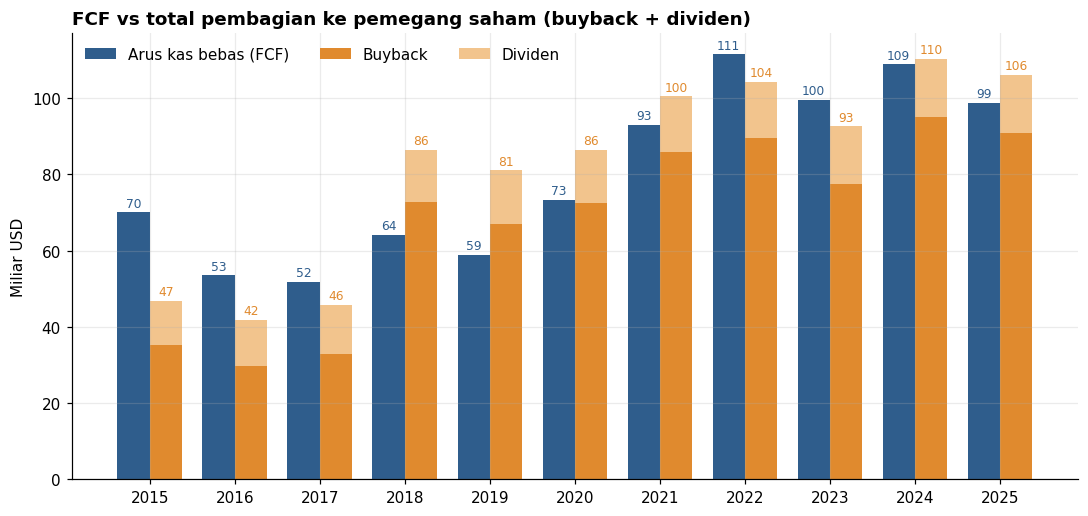

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(df)); w = .38
ax.bar(x - w/2, df.fcf/B,     w, color=BLUE,   label="Arus kas bebas (FCF)")
ax.bar(x + w/2, df.buyback/B, w, color=ORANGE, label="Buyback")
ax.bar(x + w/2, df.dividend/B, w, bottom=df.buyback/B, color="#F2C48D", label="Dividen")
ax.set_xticks(x); ax.set_xticklabels(df.index)
ax.set_ylabel("Miliar USD")
ax.set_title("FCF vs total pembagian ke pemegang saham (buyback + dividen)", loc="left", fontweight="bold")
ax.legend(frameon=False, ncol=3, loc="upper left")
for i, (f, p) in enumerate(zip(df.fcf/B, df.payout/B)):
    ax.text(i - w/2, f + 1.5, f"{f:.0f}", ha="center", fontsize=8, color=BLUE)
    ax.text(i + w/2, p + 1.5, f"{p:.0f}", ha="center", fontsize=8, color=ORANGE)
plt.tight_layout(); plt.show()


### Grafik 2 — Sudahkah Apple membagikan lebih banyak daripada yang dihasilkan? (bukti inti)

**Untuk siapa: pemberi pinjaman dan investor dividen.** Pertanyaan inti dijawab langsung di sini.

**Cara membaca:**
- Sumbu tegak = **pembagian ÷ FCF** dalam persen. Garis hitam putus-putus = ambang **100%**.
- **Titik hijau (di bawah 100%)**: pembagian lebih kecil dari kas yang dihasilkan — masih sehat.
- **Titik merah (di atas 100%)**: pembagian melebihi kas yang dihasilkan; selisihnya dibiayai simpanan atau pinjaman.
- Angka di atas tiap titik = nilai rasionya. Pola: 2015–2017 hijau, 2018–2021 merah berturut-turut (puncak 137,6% di 2019), 2022–2023 hijau, lalu 2024–2025 merah lagi.


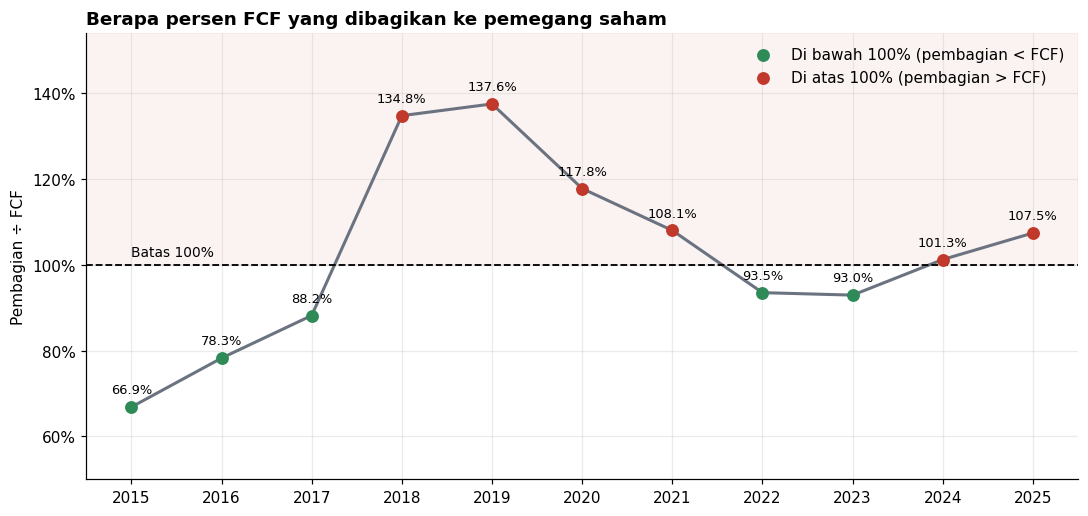

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.8))
over = df.ratio > 100
ax.axhspan(100, df.ratio.max()*1.12, color=RED, alpha=.06)
ax.plot(df.index, df.ratio, color=GREY, lw=2, zorder=2)
ax.scatter(df.index[~over], df.ratio[~over], color="#2E8B57", s=55, zorder=3, label="Di bawah 100% (pembagian < FCF)")
ax.scatter(df.index[over],  df.ratio[over],  color=RED,     s=55, zorder=3, label="Di atas 100% (pembagian > FCF)")
ax.axhline(100, color="black", ls="--", lw=1.2); ax.text(2015, 102, "Batas 100%", fontsize=9)
for fy, r in df.ratio.items():
    ax.annotate(f"{r:.1f}%", (fy, r), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xticks(df.index); ax.set_ylim(50, df.ratio.max()*1.12)
ax.set_title("Berapa persen FCF yang dibagikan ke pemegang saham", loc="left", fontweight="bold")
ax.set_ylabel("Pembagian ÷ FCF"); ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()


### Grafik 3 — Apa yang terjadi di neraca setelahnya (ekuitas vs utang jangka panjang)

**Untuk siapa: pemberi pinjaman dan analis risiko.** Kalau pembagian berlebih dibiayai simpanan dan utang, dua garis ini harus bergerak **berlawanan**: ekuitas turun, utang naik. Inilah bukti bahwa rasio di atas 100% bukan sekadar angka, tapi benar-benar berdampak ke neraca.

**Cara membaca:**
- Garis **biru = ekuitas pemegang saham**; garis **merah = utang jangka panjang non-lancar**.
- Daerah yang disorot merah = periode rasio > 100% berturut-turut (2018–2021).
- Yang dicari: **arah dua garis berlawanan** di daerah itu. Nyatanya biru turun dari 134 (2017) ke 50,7 (2022), sementara merah naik ke 109,1 (2021).


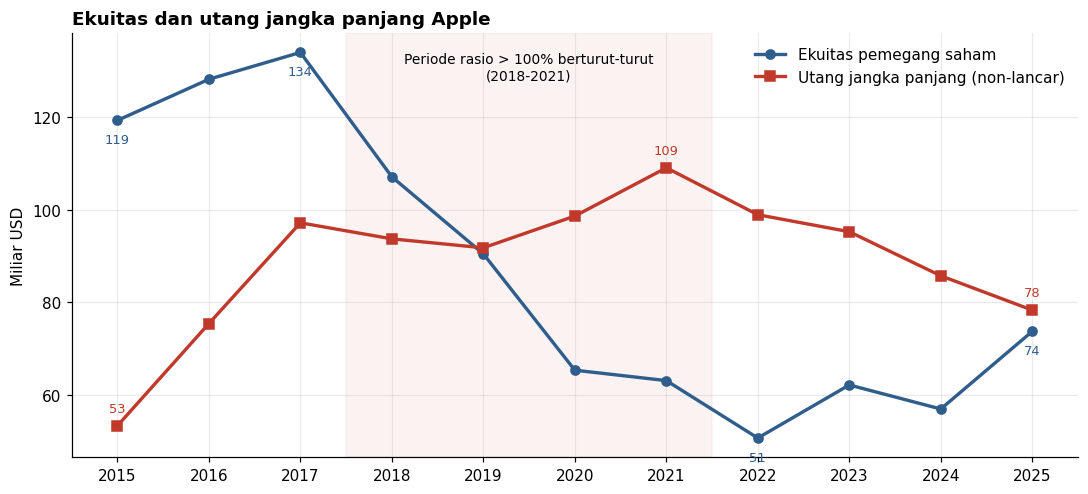

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(df.index, df.equity/B, marker="o", color=BLUE, lw=2.2, label="Ekuitas pemegang saham")
ax.plot(df.index, df.ltd/B,    marker="s", color=RED,  lw=2.2, label="Utang jangka panjang (non-lancar)")
ax.axvspan(2017.5, 2021.5, color=RED, alpha=.06)
ax.text(2019.5, ax.get_ylim()[1]*0.97, "Periode rasio > 100% berturut-turut\n(2018-2021)",
        ha="center", va="top", fontsize=9)
for s, col, dy in [(df.equity, BLUE, -15), (df.ltd, RED, 9)]:
    for fy in sorted({df.index.min(), s.idxmax(), s.idxmin(), df.index.max()}):
        ax.annotate(f"{s[fy]/B:.0f}", (fy, s[fy]/B), textcoords="offset points",
                    xytext=(0, dy), ha="center", fontsize=8.5, color=col)
ax.set_xticks(df.index); ax.set_ylabel("Miliar USD")
ax.set_title("Ekuitas dan utang jangka panjang Apple", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()


### Grafik 4 (opsional) — Apakah utang baru diterbitkan saat rasio tinggi? (424B2)

**Untuk siapa: pemberi pinjaman dan pembeli surat utang.** Grafik ini menguji hipotesis "utang baru mengikuti rasio tinggi". Form `424B2` adalah prospektus surat utang; jumlahnya dihitung dari `filings.csv` per tahun fiskal (Apple berakhir akhir September). Catatan: data filing ini hanya mencakup 2015 ke atas.

**Cara membaca:**
- **Batang abu = jumlah surat utang (424B2)** yang diterbitkan dalam tahun itu (sumbu kiri).
- **Garis merah = rasio pembagian ÷ FCF** (sumbu kanan); garis putus-putus = ambang 100%.
- Yang dicari: apakah batang tinggi bertepatan dengan garis di atas 100%. Nyatanya tidak — filing terbanyak justru 2016–2017 (rasio masih hijau), korelasi −0,19. **Hipotesis "utang baru mengikuti rasio tinggi" tidak didukung data.**


Jumlah 424B2 per tahun fiskal: {2015: 0, 2016: 8, 2017: 14, 2018: 2, 2019: 2, 2020: 6, 2021: 4, 2022: 2, 2023: 2, 2024: 0, 2025: 2}


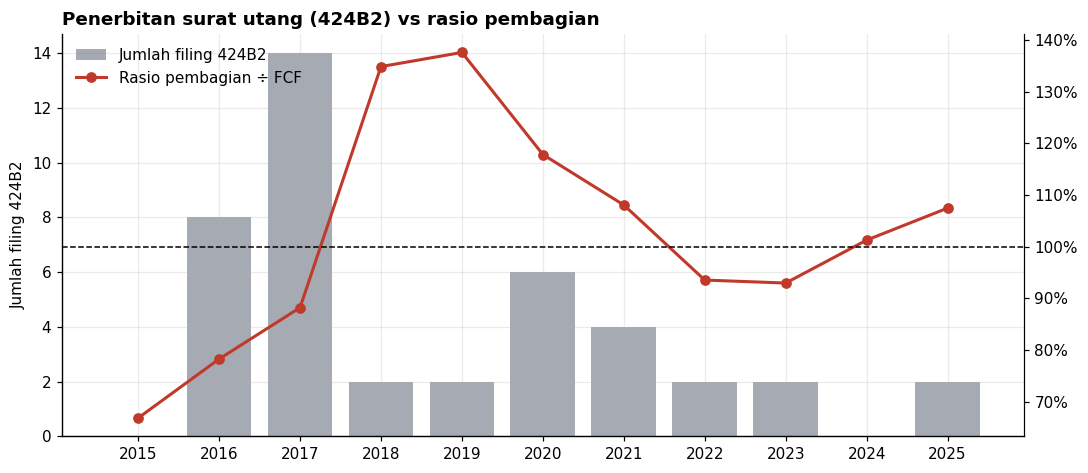

Korelasi jumlah 424B2 vs rasio: -0.19  (n=11, hanya indikatif)


In [7]:
def fiscal_year(d):                      # tahun fiskal Apple berakhir akhir September
    return d.year + (1 if d.month >= 10 else 0)

f424 = filings[filings.form == "424B2"].copy()
f424["FY"] = f424.filingDate.map(fiscal_year)
cnt = f424.groupby("FY").size().reindex(df.index, fill_value=0)
print("Jumlah 424B2 per tahun fiskal:", cnt.to_dict())

fig, ax1 = plt.subplots(figsize=(10, 4.4))
ax1.bar(cnt.index, cnt.values, color=GREY, alpha=.6, label="Jumlah filing 424B2")
ax1.set_ylabel("Jumlah filing 424B2"); ax1.set_xticks(df.index)
ax2 = ax1.twinx(); ax2.spines["right"].set_visible(True); ax2.grid(False)
ax2.plot(df.index, df.ratio, color=RED, marker="o", lw=2, label="Rasio pembagian ÷ FCF")
ax2.axhline(100, color="black", ls="--", lw=1)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
h1,l1 = ax1.get_legend_handles_labels(); h2,l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, frameon=False, loc="upper left")
ax1.set_title("Penerbitan surat utang (424B2) vs rasio pembagian", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"Korelasi jumlah 424B2 vs rasio: {np.corrcoef(cnt.values, df.ratio.values)[0,1]:.2f}  "
      f"(n={len(df)}, hanya indikatif)")


## 5. Jawaban atas pertanyaannya

Ringkasan angka yang menjawab pertanyaan di bagian judul:

In [8]:
over_years = df.index[df.ratio > 100].tolist()
print(f"Tahun dengan rasio > 100% : {over_years}  ({len(over_years)} dari {len(df)} tahun)")
print(f"Puncak                    : {df.ratio.idxmax()} = {df.ratio.max():.1f}%")
print(f"Surplus 2015-2017         : {-df.loc[2015:2017,'gap'].sum()/B:,.1f} miliar USD (FCF > pembagian)")
print(f"Kelebihan 2018-2025       : {df.loc[2018:2025,'gap'].sum()/B:,.1f} miliar USD (pembagian > FCF)")
print(f"Net 2015-2025             : {df.gap.sum()/B:,.1f} miliar USD lebih banyak dibagikan daripada FCF")
print()
print(f"Ekuitas puncak            : {df.equity.idxmax()} = {df.equity.max()/B:.1f} miliar USD")
print(f"Ekuitas terendah          : {df.equity.idxmin()} = {df.equity.min()/B:.1f} miliar USD")
print(f"Utang jangka panjang puncak: {df.ltd.idxmax()} = {df.ltd.max()/B:.1f} miliar USD")
print(f"2025                       : ekuitas {df.equity[2025]/B:.1f} | utang {df.ltd[2025]/B:.1f} miliar USD")
print()
print(f"Dividen  2015 -> 2025      : {df.dividend[2015]/B:.1f} -> {df.dividend[2025]/B:.1f} miliar (stabil)")
print(f"Buyback min/max            : {df.buyback.min()/B:.1f} ({df.buyback.idxmin()}) / "
      f"{df.buyback.max()/B:.1f} ({df.buyback.idxmax()}) miliar (berayun)")
print(f"Koefisien variasi          : dividen {df.dividend.std()/df.dividend.mean():.2f} | "
      f"buyback {df.buyback.std()/df.buyback.mean():.2f}")


Tahun dengan rasio > 100% : [2018, 2019, 2020, 2021, 2024, 2025]  (6 dari 11 tahun)
Puncak                    : 2019 = 137.6%
Surplus 2015-2017         : 40.9 miliar USD (FCF > pembagian)
Kelebihan 2018-2025       : 59.5 miliar USD (pembagian > FCF)
Net 2015-2025             : 18.6 miliar USD lebih banyak dibagikan daripada FCF

Ekuitas puncak            : 2017 = 134.0 miliar USD
Ekuitas terendah          : 2022 = 50.7 miliar USD
Utang jangka panjang puncak: 2021 = 109.1 miliar USD
2025                       : ekuitas 73.7 | utang 78.3 miliar USD

Dividen  2015 -> 2025      : 11.6 -> 15.4 miliar (stabil)
Buyback min/max            : 29.7 (2016) / 94.9 (2024) miliar (berayun)
Koefisien variasi          : dividen 0.09 | buyback 0.36


## 6. Solusi dan batasan

### Solusi — arah tindakan

Ini pertimbangan yang masuk akal bagi tiap pihak, bukan hasil hitungan dari data:

| Solusi | Penjelasan | Pihak terbantu |
|---|---|---|
| Pasang batas pembagian berbasis FCF | Misalnya rata-rata beberapa tahun tidak melewati 100%, bukan berpatokan pada laba | Dewan direksi / CFO |
| Pisahkan dividen dan buyback | Dividen dijaga stabil (11,6 → 15,4 miliar); buyback dibuat fleksibel mengikuti FCF (koefisien variasi: dividen 0,09 vs buyback 0,36) | Dewan direksi / CFO |
| Pantau ekuitas dan utang sebagai alarm | Kalau ekuitas turun dan utang naik bersamaan, itu tanda pola 2018-2021 terulang | Pemberi pinjaman, analis risiko |
| Perhatikan 2024-2025 | Rasio naik lagi di atas 100% (101,3% → 107,5%); layak dicermati sebelum melebar seperti 2019 | Investor dividen |

### Batasan analisis

- **Rasio > 100% tidak otomatis buruk.** Apple memegang simpanan dalam bentuk sekuritas yang **tidak dihitung** di sini (data hanya mencakup kas dan setara kas), jadi data ini belum bisa menyimpulkan Apple kekurangan uang.
- **Data tidak menjelaskan alasan** di balik keputusan Apple membagikan lebih banyak — itu perlu dicari dari isi laporan 10-K dan sumber lain.
- **Tidak ada harga saham** dalam dataset, sehingga tidak bisa dinilai apakah buyback dilakukan di harga yang menguntungkan.
- **Korelasi dengan penerbitan 424B2 hanya indikatif** (11 titik data), dan filing 424B2 justru terbanyak di 2016-2017 saat rasio masih di bawah 100% — hipotesis "utang baru mengikuti rasio tinggi" tidak didukung data.
- **Data 2014 tidak lengkap** untuk arus kas operasi, sehingga analisis dimulai dari 2015.

> Ini bukan saran investasi. Keputusan membeli/menjual saham perlu mempertimbangkan banyak hal di luar data ini.
